Create functions to perform Monte Carlo Integration, Trapezoidal Integration, Simpson's Rule integration
- Input: Function, bounds, # of points/division
- Output: Total area bounded by curve, x-axis, and x-bounds, signed area (integral)
- Should accomodate to any continuous function
- Check with scipy integrate

Report figures:
2 plots per function; 3 functions; 6 total plots
1.  |error vs. n|for trapezoidal and simpson's rule
3. Monte carlo plot, blue above x-axis, red= below x-axis

Report discussion - explain the figures


In [21]:
import numpy as np
import math
from scipy.integrate import quad
import matplotlib.pyplot as plt

In [2]:
#Test functions
def f(x): #x=0, x=3/2
    return np.sqrt(9-4*x**2)
def g(x): #x=-2, x=2
    return -x**2+1
def h(x): #x=0. x= pi
    return np.cos(x)*np.sqrt(x)

In [32]:
#integration functions from Gezerlis
#f = function, a,b = are boundary values, n=no. of points/divisions
def trapezoid (f,a,b,n): #1/2[f(0)+f(n-1)]+ sum of f(i) from i=1 to i=n-2
    h = (b-a)/(n-1) #height/grid spacing
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0]=0.5; cs[-1]=0.5
    contribs = cs*f(xs) #boundary values f(0) and f(n-1) are multiplied by 1/2
    total_area = h * np.sum(abs(contribs))
    signed_integral = h*np.sum(contribs) 
    return total_area, signed_integral
    
def simpson_thirds (f,a,b,n): #weights = h/3[1,4,2,4,...,2,4,1]
    h = (b-a)/(n-1) #grid spacing
    xs = a+np.arange(n)*h
    cs= 2*np.ones(n)
    cs[1::2] =4; cs[0] = 0.5; cs[-1]=1
    contribs = cs*f(xs)
    total_area = (h/3)*np.sum(abs(contribs))
    signed_integral = (h/3)*np.sum(contribs)
    return total_area, signed_integral

def simpson_three_eighths (f,a,b,n):#weights = 3/8*[1,3,3,2,..., ]
    h = (b-a)/(n-1)
    xs = a+np.arange(n)*h
    cs = np.full(n,3)#creates an array of all 3s
    cs[0] = 1; cs[-1] = 1 # boundaries are 1
    cs[3:-1:3] = 2 # every third element is 2
    contribs = cs*f(xs)
    signed_integral = (3*h/8) *np.sum(contribs)
    total_area = (3*h/8)*np.sum(abs(contribs))
    return total_area, signed_integral
    
def montecarlo(f, a, b, n, option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)
    
    if option == "uniform":
        fs_signed = f(us)
        fs_area = np.abs(f(us))
        
        signed_integral = (b - a) * np.mean(fs_signed)
        total_area = (b - a) * np.mean(fs_area)
        return total_area, signed_integral
    else:
        c0 = 4 - 2 * np.sqrt(2)
        c1 = -6 + 4 * np.sqrt(2)
        xs = (-c0 + np.sqrt(2 * c1 * us + c0**2)) / c1
        
        weights = c0 + c1 * xs
        fs_signed = f(xs) / weights
        fs_area = np.abs(f(xs)) / weights
        
        fbar_signed, _ = stats(fs_signed)
        fbar_area, _ = stats(fs_area)
        
        signed_integral = (b - a) * fbar_signed
        total_area = (b - a) * fbar_area
        return total_area, signed_integral

In [4]:
quad(g,-2,2)

(-1.3333333333333335, 4.465845366792915e-14)

In [5]:
trapezoid(g,-2,2,100)

(4.001228487301338, -1.3344216576539822)

In [6]:
simpson_thirds(g,-2,2,100)

(3.940622426695278, -1.2738155970479215)

In [7]:
simpson_three_eighths(g,-2,2,100)

(4.000018550982739, -1.3333333333333341)

In [33]:
montecarlo(g,-2,2,100)

(4.227792366260232, -1.7560467770983343)

In [83]:
#function to run diff integration methods and calculate error on the 3 f,g,h with varying step sizes
def error (f,a,b,n):
    exact, _ = quad(f,a,b)
    trapezoid_error = []
    simpson1_error = []
    simpson2_error = []
    for steps in n: #evaluates integrals
        _, trap = trapezoid(f,a,b,steps)
        _, simp1 = simpson_thirds(f,a,b,steps)
        _, simp2 = simpson_three_eighths(f,a,b,steps)

    #calculates errors
        trapezoid_error.append(abs(trap-exact))
        simpson1_error.append(abs(simp1-exact))
        simpson2_error.append(abs(simp2-exact))

    #Plotting
    plt.scatter(n, trapezoid_error, marker='o', label='Trapezoidal Integration')
    plt.scatter(n, simpson1_error, marker='s', label="Simpson's 1/3 rule")
    plt.scatter(n, simpson2_error, marker = '^', label = "Simpson's 3/8 rule")
    plt.yscale("log")
    plt.xscale("log")
    plt.xlabel('N')
    plt.ylabel('Absolute Error')
    plt.title("|error vs. n| for Trapezoidal and Simpson's (1/3 and 3/8) methods")
    plt.legend()
    return plt.show()

/tmp/ipykernel_6654/2542076418.py:3: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(9-4*x**2)


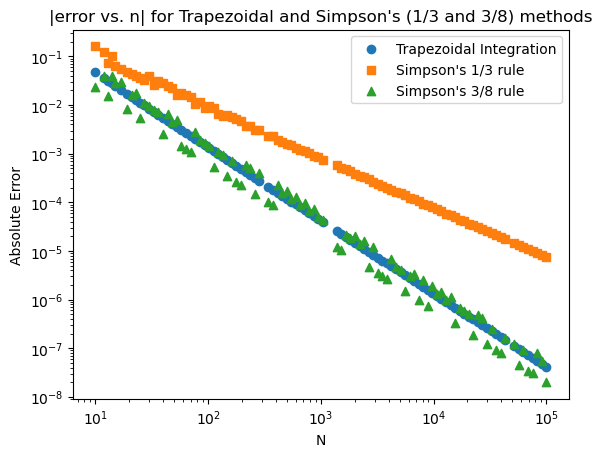

In [84]:
N = np.logspace(1, 5, 100).astype(int)
N = np.unique(N)
error(f,0,3/2,N)

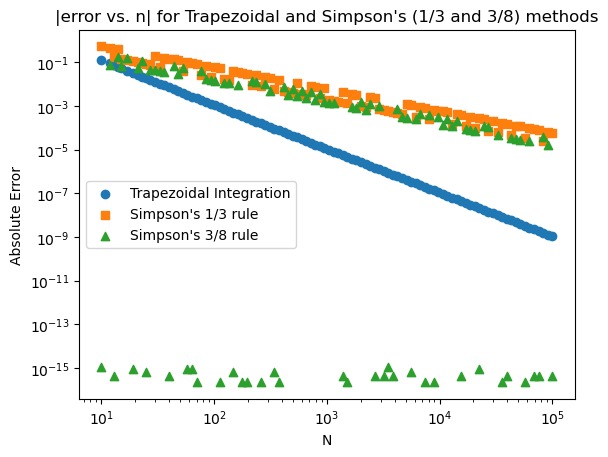

In [85]:
error(g,-2,2,N)

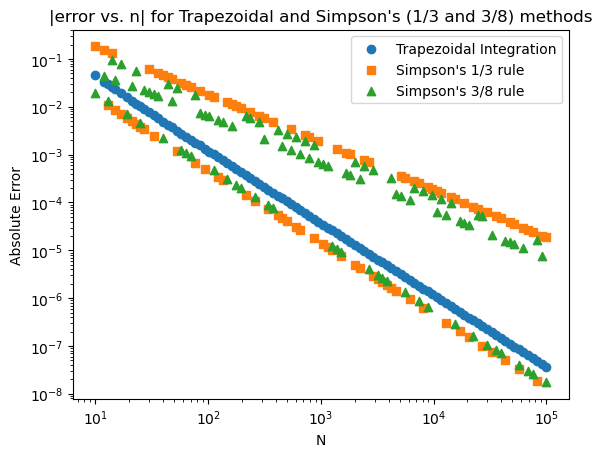

In [86]:
error(h,0,np.pi,N)